## Comparision of density and T profiles from Burrabal 2018


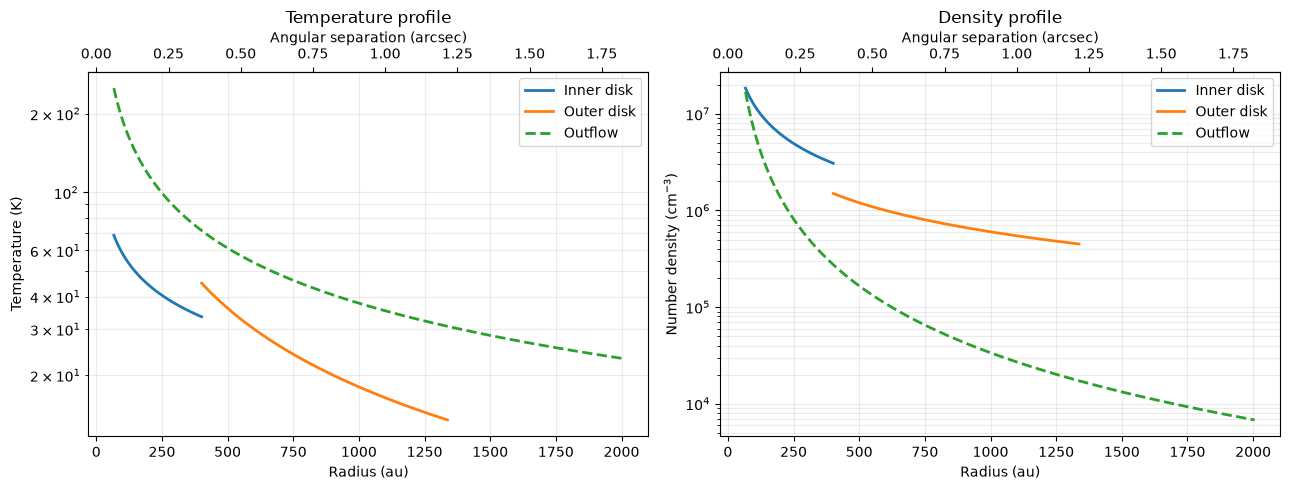

In [2]:

import numpy as np
import matplotlib.pyplot as plt

AU = 1.495978707e13  # cm
distance_pc = 1100

# Physical radii in au
Ri = 6e15 / AU
Ro = 2e16 / AU
Rof = 2.5e16 / AU

# Reference radii in au
Rref_inner = 5e15 / AU
Rref_outer = 1e16 / AU

# Radial grids in au
p_inner = np.geomspace(1e15 / AU, Ri, 300)
p_outer = np.geomspace(Ri, Ro, 300)
r_outflow = np.geomspace(1e15 / AU, 3e16 / AU, 300)

# Temperature profiles
T_inner = 36 * (Rref_inner / p_inner)**0.4
T_outer = 27 * (Rref_outer / p_outer)**1.0
T_outflow = 50 * (Rref_outer / r_outflow)**0.7

# Number density profiles
n_inner = 3.7e6 * (Rref_inner / p_inner)
n_outer = 9e5 * (Rref_outer / p_outer)
n_outflow = 8.5e4 * (Rref_outer / r_outflow)**2.3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

profiles = [
    (p_inner, T_inner, n_inner, "Inner disk", "tab:blue"),
    (p_outer, T_outer, n_outer, "Outer disk", "tab:orange"),
    (r_outflow, T_outflow, n_outflow, "Outflow", "tab:green"),
]

for ax, quantity in zip(axes, [1, 2]):
    for profile in profiles:
        radius, T, n, label, color = profile
        values = T if quantity == 1 else n

        ax.plot(radius, values, lw=2,
                color=color,
                ls="--" if label == "Outflow" else "-",
                label=label)

    
    ax.set_yscale("log")
    ax.set_xlabel("Radius (au)")
    ax.grid(alpha=0.25, which="both")
    ax.legend()

    # Secondary axis: au -> arcseconds
    secax = ax.secondary_xaxis(
        "top",
        functions=(
            lambda au: au / distance_pc,
            lambda arcsec: arcsec * distance_pc
        )
    )
    secax.set_xlabel("Angular separation (arcsec)")

axes[0].set_ylabel("Temperature (K)")
axes[0].set_title("Temperature profile")

axes[1].set_ylabel(r"Number density (cm$^{-3}$)")
axes[1].set_title("Density profile")

plt.tight_layout()
plt.savefig("profiles_1100pc.png", dpi=300)
plt.show()
